# Taller · De los datos a un dashboard publicado

**Programación — ADMI 1301**

Trabajarás con las **2.000 ventas de una cadena de papelerías en 2025**. En este taller vas a:

1. **Graficar** (6 ejercicios con `groupby`, `crosstab` y `pivot_table`).
2. **Organizar** tus gráficos en una sola figura con `subplots`: tu *dashboard*.
3. **Embellecerlo con prompts** para Gemini, en el mismo Colab.
4. **Elegir tu versión favorita**, escribir tus conclusiones y **publicar tu notebook en GitHub**.

Las instrucciones completas están en la guía en Word. Aquí encuentras lo esencial de cada ejercicio y una **verificación** (`assert`) para saber si vas bien.

## 0. Preparación
Ejecuta la celda y sube el archivo **`ventas_papelerias_2025.csv`**.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from IPython.display import display

subidos = files.upload()   # selecciona ventas_papelerias_2025.csv

df = pd.read_csv("ventas_papelerias_2025.csv")
df["fecha"] = pd.to_datetime(df["fecha"])
df["mes"] = df["fecha"].dt.month        # 1 = enero ... 12 = diciembre
df.head()

Saving ventas_papelerias_2025.csv to ventas_papelerias_2025 (1).csv


,id_venta,fecha,ciudad,canal,segmento,vendedor,producto,categoria,metodo_pago,cantidad,precio_unitario,descuento,total,mes
0,V0001,2025-01-01,Cali,Tienda,Corporativo,Julián Cortés,Resma carta,Papel,Transferencia,6,18000,0.10,97200,1
1,V0002,2025-01-01,Medellín,Telefónico,Corporativo,Andrés Rojas,Carpeta,Organización,Transferencia,21,2500,0.00,52500,1
2,V0003,2025-01-01,Barranquilla,Telefónico,Mayorista,Mateo Peña,Cuaderno,Papel,Transferencia,65,3500,0.10,204750,1
3,V0004,2025-01-02,Bucaramanga,Online,Minorista,Isabela Mora,Colores x12,Arte,Tarjeta,6,8500,0.00,51000,1
4,V0005,2025-01-02,Medellín,Telefónico,Mayorista,Andrés Rojas,Esfero,Escritura,Tarjeta,67,1200,0.15,68340,1


**Conoce tus datos** antes de graficar: cuántas filas hay, qué columnas, qué valores tiene cada categoría.

In [ ]:
print(df.shape)
df.info()
for col in ["ciudad", "canal", "segmento", "categoria", "metodo_pago"]:
    print(col, "->", sorted(df[col].unique()))

(2000, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   id_venta         2000 non-null   object        
 1   fecha            2000 non-null   datetime64[ns]
 2   ciudad           2000 non-null   object        
 3   canal            2000 non-null   object        
 4   segmento         2000 non-null   object        
 5   vendedor         2000 non-null   object        
 6   producto         2000 non-null   object        
 7   categoria        2000 non-null   object        
 8   metodo_pago      2000 non-null   object        
 9   cantidad         2000 non-null   int64         
 10  precio_unitario  2000 non-null   int64         
 11  descuento        2000 non-null   float64       
 12  total            2000 non-null   int64         
 13  mes              2000 non-null   int32         
dtypes: datetime64[ns](1), float64

---
# Parte A · Seis gráficos
En cada ejercicio: **(1)** prepara una tabla con `groupby`, `crosstab` o `pivot_table`, **(2)** guárdala en la variable indicada, **(3)** grafícala. Ponle **título** a cada gráfico.

### Ejercicio 1 · Top 5 de productos *(barras horizontales)*
**Contexto.** La gerente de compras debe decidir en qué productos concentrar el inventario del próximo año.

**Tarea.** Calcula los ingresos (`total`) por `producto`, quédate con los **5 mayores** y grafícalos en barras horizontales. Guarda la tabla en **`top_productos`**.

*Herramientas:* `groupby`, `sum`, `sort_values`, `head`, `.plot.barh()`

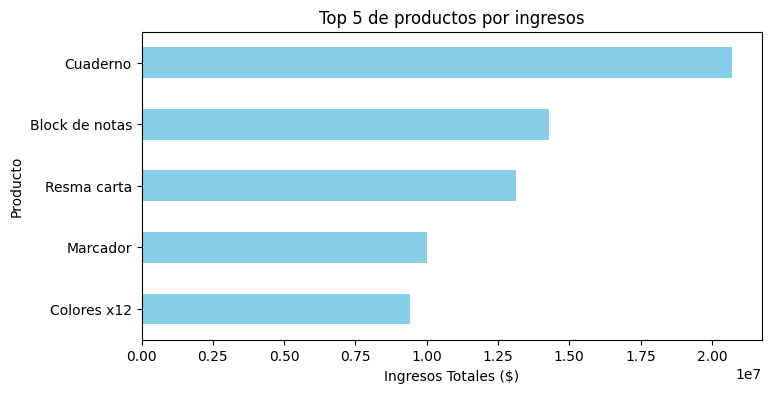

In [ ]:
# Ejercicio 1
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)

plt.figure(figsize=(8, 4))
top_productos.sort_values().plot.barh(color="skyblue")
plt.title("Top 5 de productos por ingresos")
plt.xlabel("Ingresos Totales ($)")
plt.ylabel("Producto")
plt.show()


### Ejercicio 2 · Ingresos mes a mes: Bogotá vs Medellín *(líneas)*
**Contexto.** La dirección regional quiere comparar la evolución de sus dos ciudades principales durante el año.

**Tarea.** **Selecciona** solo las ventas de Bogotá y Medellín (`isin`). Con una **tabla dinámica** pon los meses en las filas, las ciudades en las columnas y la suma de `total` como valores. Guárdala en **`ing_mes_ciudad`** y grafícala como líneas con marcadores.

*Herramientas:* filtrado con `isin`, `pivot_table`, `.plot.line(marker="o")`

<Figure size 800x400 with 0 Axes>

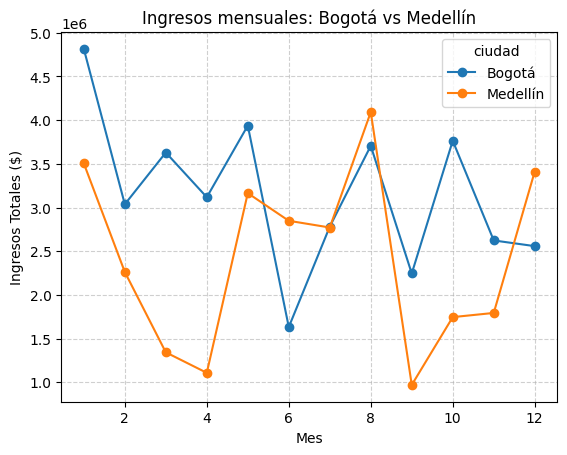

In [ ]:
# Ejercicio 2
ing_mes_ciudad = df[df["ciudad"].isin(["Bogotá", "Medellín"])].pivot_table(
    index="mes", columns="ciudad", values="total", aggfunc="sum"
)

plt.figure(figsize=(8, 4))
ing_mes_ciudad.plot.line(marker="o")
plt.title("Ingresos mensuales: Bogotá vs Medellín")
plt.xlabel("Mes")
plt.ylabel("Ingresos Totales ($)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()


### Ejercicio 3 · ¿Por qué canal se vende más? *(gráfico de pie)*
**Contexto.** La empresa evalúa si invierte más en su tienda online o en la atención telefónica.

**Tarea.** Calcula los ingresos totales por `canal`, guárdalos en **`ing_canal`** y grafica la participación de cada canal con un gráfico de pie que muestre los **porcentajes con un decimal**.

*Herramientas:* `groupby`, `.plot.pie(autopct=...)`

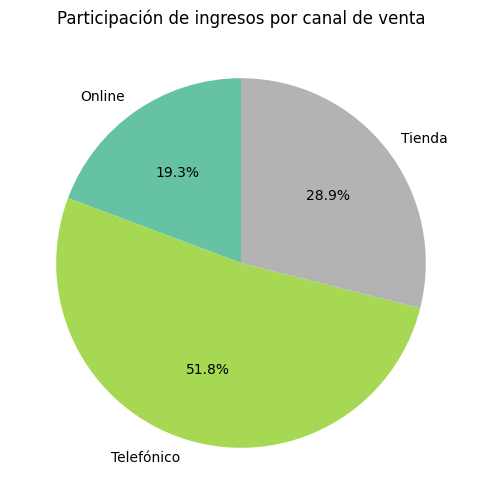

In [ ]:
# Ejercicio 3
ing_canal = df.groupby("canal")["total"].sum()

plt.figure(figsize=(6, 6))
ing_canal.plot.pie(autopct="%1.1f%%", startangle=90, cmap="Set2")
plt.title("Participación de ingresos por canal de venta")
plt.ylabel("")
plt.show()


### Ejercicio 4 · ¿Cada segmento compra lo mismo? *(barras apiladas)*
**Contexto.** El área comercial sospecha que los clientes corporativos compran productos distintos a los minoristas.

**Tarea.** Con `pd.crosstab` cuenta las ventas por `segmento` (filas) y `categoria` (columnas), **normalizadas por fila** y expresadas en **porcentaje** (de 0 a 100). Guarda la tabla en **`tabla_seg_cat`** y grafícala en barras **apiladas**.

*Herramientas:* `pd.crosstab(..., normalize="index")`, `.plot.bar(stacked=True)`

<Figure size 900x500 with 0 Axes>

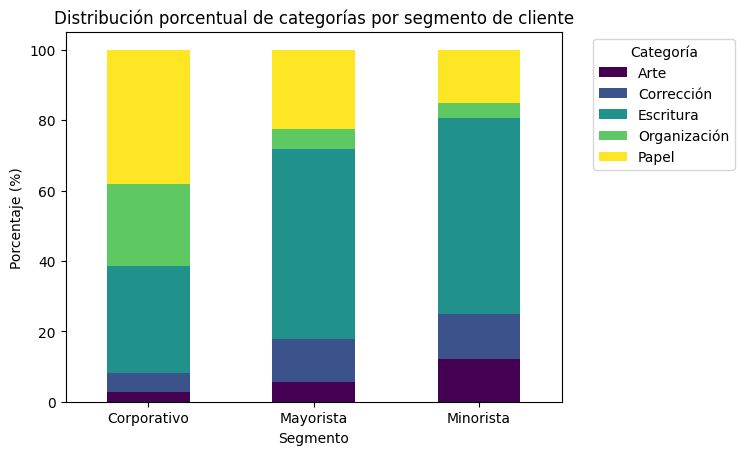

In [ ]:
# Ejercicio 4
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100

plt.figure(figsize=(9, 5))
tabla_seg_cat.plot.bar(stacked=True, colormap="viridis")
plt.title("Distribución porcentual de categorías por segmento de cliente")
plt.xlabel("Segmento")
plt.ylabel("Porcentaje (%)")
plt.legend(title="Categoría", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.xticks(rotation=0)
plt.show()


### Ejercicio 5 · Productividad de los vendedores *(dispersión)*
**Contexto.** Recursos humanos revisa qué vendedores concretan más ventas y cuáles venden tickets más altos.

**Tarea.** Con `groupby` por `vendedor` y `ciudad`, calcula para cada vendedor el **número de ventas** (`n_ventas`) y el **valor promedio de sus ventas** (`ticket_prom`). Guarda la tabla en **`vend`** (con índice normal: usa `reset_index()`). Haz una dispersión (`n_ventas` en X, `ticket_prom` en Y) con un **color por ciudad** y leyenda.

*Herramientas:* `groupby().agg(nombre=("columna", "función"))`, `reset_index`, `plt.scatter` dentro de un `for`

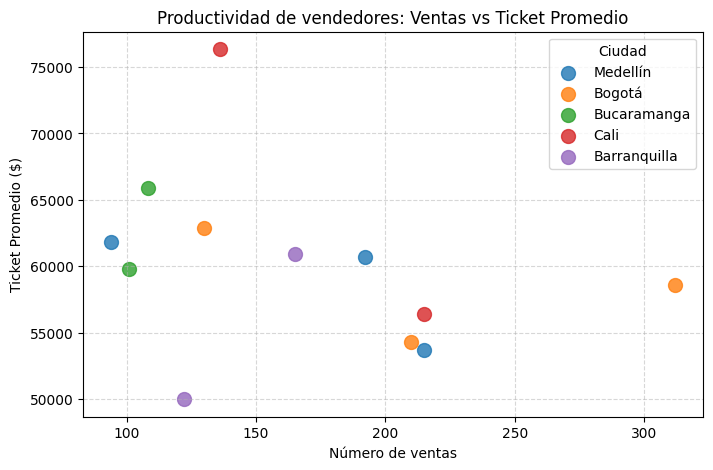

In [ ]:
# Ejercicio 5
vend = df.groupby(["vendedor", "ciudad"]).agg(
    n_ventas=("id_venta", "count"),
    ticket_prom=("total", "mean")
).reset_index()

plt.figure(figsize=(8, 5))
ciudades = vend["ciudad"].unique()
colores = plt.cm.tab10(range(len(ciudades)))

for ciudad, color in zip(ciudades, colores):
    subset = vend[vend["ciudad"] == ciudad]
    plt.scatter(subset["n_ventas"], subset["ticket_prom"], label=ciudad, s=100, color=color, alpha=0.8)

plt.title("Productividad de vendedores: Ventas vs Ticket Promedio")
plt.xlabel("Número de ventas")
plt.ylabel("Ticket Promedio ($)")
plt.legend(title="Ciudad")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


### Ejercicio 6 · ¿Qué tan grandes son las ventas de cada segmento? *(diagrama de cajas)*
**Contexto.** Para planear el segundo semestre, finanzas quiere ver cómo se distribuye el valor de las ventas por tipo de cliente.

**Tarea.** **Selecciona** solo las ventas del **segundo semestre** (`mes` de 7 a 12) y guárdalas en **`sem2`**. Haz un diagrama de cajas del `total` por `segmento`, **sin mostrar los valores atípicos** (`showfliers=False`).

*Herramientas:* filtro con `>=`, `.boxplot(column=..., by=...)`

<Figure size 800x500 with 0 Axes>

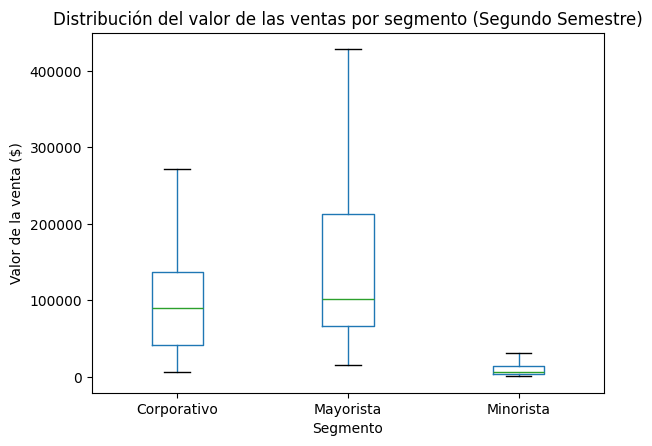

In [ ]:
# Ejercicio 6
sem2 = df[df["mes"] >= 7]

plt.figure(figsize=(8, 5))
sem2.boxplot(column="total", by="segmento", grid=False, showfliers=False)
plt.title("Distribución del valor de las ventas por segmento (Segundo Semestre)")
plt.suptitle("") # Elimina el título automático adicional de pandas
plt.xlabel("Segmento")
plt.ylabel("Valor de la venta ($)")
plt.show()


---
# Parte B · Todo en una sola figura (`subplots`)
### Ejercicio 7 · Organiza tus 6 gráficos en una cuadrícula de 2 × 3
**Contexto.** La gerente quiere ver todo en **una sola imagen** para presentarla en la junta.

**Tarea.** Crea una figura con `fig, axs = plt.subplots(2, 3, figsize=(18, 10))` y dibuja cada gráfico en su posición pasando **`ax=axs[fila, columna]`**. Agrega un título general con `fig.suptitle(...)` y termina con `plt.tight_layout()`.

**Importante:** escribe el código en la celda que empieza con `%%writefile figura_base.py` (así el programa guarda tu código en un archivo, que usarás en la Parte C). Luego ejecuta la celda siguiente (`%run -i figura_base.py`) para ver la figura.

*Pistas:* `plot.barh(ax=axs[0, 0])` · `plot.pie(...)` también acepta `ax` · para el boxplot: `boxplot(column=..., by=..., ax=...)` · para la dispersión: `axs[1, 1].scatter(...)`

In [ ]:

%%writefile figura_base.py
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 3, figsize=(18, 10))

top_productos.sort_values().plot.barh(ax=axs[0, 0], color="skyblue")
axs[0, 0].set_title("Top 5 de productos por ingresos")
axs[0, 0].set_xlabel("Ingresos Totales ($)")
axs[0, 0].set_ylabel("Producto")

ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o")
axs[0, 1].set_title("Ingresos mensuales: Bogotá vs Medellín")
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")
axs[0, 1].grid(True, linestyle="--", alpha=0.6)

ing_canal.plot.pie(ax=axs[0, 2], autopct="%1.1f%%", startangle=90, cmap="Set2")
axs[0, 2].set_title("Participación por canal de venta")
axs[0, 2].set_ylabel("")

tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, colormap="viridis")
axs[1, 0].set_title("Categorías por segmento (%)")
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje (%)")
axs[1, 0].tick_params(axis='x', rotation=0)
axs[1, 0].legend(title="Categoría", fontsize=8)

ciudades = vend["ciudad"].unique()
colores = plt.cm.tab10(range(len(ciudades)))
for ciudad, color in zip(ciudades, colores):
    subset = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(subset["n_ventas"], subset["ticket_prom"], label=ciudad, s=80, color=color, alpha=0.8)
axs[1, 1].set_title("Productividad de vendedores")
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket Promedio ($)")
axs[1, 1].legend(title="Ciudad", fontsize=8)
axs[1, 1].grid(True, linestyle="--", alpha=0.5)

sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], grid=False, showfliers=False)
axs[1, 2].set_title("Valor de ventas por segmento (Sem 2)")
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Total ($)")

fig.suptitle("Ventas de la cadena de papelerías 2025", fontsize=18, fontweight="bold")
plt.tight_layout()



Overwriting figura_base.py


In [ ]:
%run -i figura_base.py

In [ ]:
# ✅ Verificación
assert len(fig.axes) >= 6, f"La figura debe tener 6 gráficos, tiene {len(fig.axes)}"
print("Ejercicio 7 correcto ✔")

Ejercicio 7 correcto ✔


---
# Parte C · Hazla ver bonita con prompts
Ahora **tú escribes el prompt y Gemini reescribe el código** de tu figura para que se vea profesional, casi como un dashboard.


### Herramientas *(ya están hechas)*
Ejecuta esta celda. Define dos funciones:

- **`embellecer(prompt, nombre)`**: envía tu prompt **junto con tu código de `figura_base.py`**, ejecuta el código nuevo que devuelve Gemini y muestra la figura. Cada versión queda guardada en `VERSIONES[nombre]`.
- **`mostrar(nombre)`**: vuelve a dibujar una versión guardada.

In [ ]:
import re

VERSIONES = {}      # aquí se guarda el código de cada versión ("v1", "v2", ...)

REGLAS_FIGURA = """

Reglas técnicas obligatorias:
- Usa solo pandas y matplotlib (y numpy si lo necesitas). No instales otras librerías.
- Los datos ya están cargados en el DataFrame `df` (columnas: id_venta, fecha, ciudad, canal, segmento, vendedor,
  producto, categoria, metodo_pago, cantidad, precio_unitario, descuento, total, mes). No cargues archivos.
- Conserva los MISMOS 6 gráficos y los mismos datos del código actual (puedes recalcular las tablas con el mismo código);
  cambia solo la presentación.
- La figura debe quedar en una variable llamada `fig` (2 filas x 3 columnas).
- NO uses plt.show() ni guardes archivos.
- Entrega solo UN bloque de código Python completo.
"""


def extraer_codigo(texto):
    """Devuelve el contenido del primer bloque de código ``` de la respuesta."""
    bloque = re.search(r"```(?:python)?\s*\n(.*?)```", texto, re.S)
    return bloque.group(1) if bloque else texto


def dibujar(codigo):
    """Ejecuta el código de una figura y la muestra."""
    import numpy as np
    plt.close("all")
    espacio = {"df": df, "pd": pd, "plt": plt, "np": np}
    exec(codigo, espacio)
    figura = espacio["fig"]
    display(figura)
    plt.close(figura)


def embellecer(prompt, nombre, modelo="gemini-flash-latest"):
    """Gemini reescribe tu figura según tu prompt; se ejecuta, se muestra y se guarda en VERSIONES."""
    codigo_actual = open("figura_base.py", encoding="utf-8").read()
    contenido = f"{prompt}\n\nEste es mi código actual:\n```python\n{codigo_actual}\n```{REGLAS_FIGURA}"
    respuesta = client.models.generate_content(model=modelo, contents=contenido)
    codigo = extraer_codigo(respuesta.text)
    try:
        dibujar(codigo)
    except Exception as e:
        print("❌ El código de Gemini falló:", type(e).__name__, e)
        print("Copia ese error en tu siguiente prompt y pídele que lo corrija.")
        return
    VERSIONES[nombre] = codigo
    print(f"✔ Versión '{nombre}' guardada")


def mostrar(nombre):
    """Vuelve a dibujar una versión guardada."""
    dibujar(VERSIONES[nombre])

### Ejercicio 8 · Tu primer prompt de estilo
Completa las secciones de `prompt_v1`. Sé **específico**: "usa una paleta de azules y naranja" funciona mejor que "hazlo bonito".

- **PÚBLICO Y OBJETIVO:** quién verá la figura y para qué.
- **PALETA Y TIPOGRAFÍA:** colores (por ciudad, por producto…), fondo, tamaños de letra.
- **TÍTULOS:** que cada gráfico tenga un título que diga la **conclusión** (por ejemplo, "Bogotá lidera las ventas"), no solo el nombre.
- **EJES Y NÚMEROS:** formatos con separador de miles o "$ 12 M", etiquetas de ejes claras.
- **LIMPIEZA VISUAL:** quitar bordes y marcos innecesarios, cuadrícula suave, valores sobre las barras.

In [ ]:
%%writefile figura_v1.py
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig.patch.set_facecolor('#f8f9fa')

# 1. Top 5 productos
top_productos.sort_values().plot.barh(ax=axs[0, 0], color='#2b5c8f')
axs[0, 0].set_title("El Cuaderno lidera ampliamente las ventas", fontsize=12, fontweight='bold', loc='left')
axs[0, 0].set_xlabel("Ingresos Totales ($)", fontsize=10)
axs[0, 0].set_ylabel("Producto", fontsize=10)
axs[0, 0].spines['top'].set_visible(False)
axs[0, 0].spines['right'].set_visible(False)

# 2. Ingresos mensuales: Bogotá vs Medellín
ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", linewidth=2.5)
axs[0, 1].set_title("Bogotá supera con consistencia a Medellín", fontsize=12, fontweight='bold', loc='left')
axs[0, 1].set_xlabel("Mes", fontsize=10)
axs[0, 1].set_ylabel("Ingresos ($)", fontsize=10)
axs[0, 1].grid(True, linestyle="--", alpha=0.5)
axs[0, 1].spines['top'].set_visible(False)
axs[0, 1].spines['right'].set_visible(False)
axs[0, 1].legend(frameon=False)

# 3. Canales de venta
ing_canal.plot.pie(ax=axs[0, 2], autopct="%1.1f%%", startangle=90, colors=['#2b5c8f', '#e67e22', '#27ae60'])
axs[0, 2].set_title("El canal Telefónico concentra más de la mitad", fontsize=12, fontweight='bold', loc='left')
axs[0, 2].set_ylabel("")

# 4. Segmento vs Categoría
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, colormap="Blues")
axs[1, 0].set_title("Distribución de categorías por segmento", fontsize=12, fontweight='bold', loc='left')
axs[1, 0].set_xlabel("Segmento", fontsize=10)
axs[1, 0].set_ylabel("Porcentaje (%)", fontsize=10)
axs[1, 0].tick_params(axis='x', rotation=0)
axs[1, 0].legend(title="Categoría", fontsize=8, frameon=False)
axs[1, 0].spines['top'].set_visible(False)
axs[1, 0].spines['right'].set_visible(False)

# 5. Productividad de vendedores
ciudades = vend["ciudad"].unique()
colores_c = {'Bogotá': '#2b5c8f', 'Medellín': '#e67e22', 'Cali': '#27ae60', 'Barranquilla': '#f1c40f', 'Bucaramanga': '#8e44ad'}
for ciudad in ciudades:
    subset = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(subset["n_ventas"], subset["ticket_prom"], label=ciudad, s=90, color=colores_c.get(ciudad, '#333333'), alpha=0.85)
axs[1, 1].set_title("Productividad y ticket promedio por vendedor", fontsize=12, fontweight='bold', loc='left')
axs[1, 1].set_xlabel("Número de ventas", fontsize=10)
axs[1, 1].set_ylabel("Ticket Promedio ($)", fontsize=10)
axs[1, 1].legend(title="Ciudad", fontsize=8, frameon=False)
axs[1, 1].grid(True, linestyle="--", alpha=0.5)
axs[1, 1].spines['top'].set_visible(False)
axs[1, 1].spines['right'].set_visible(False)

# 6. Diagrama de cajas semestre 2
sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], grid=False, showfliers=False, patch_artist=True, boxprops=dict(facecolor='#aec7e8', color='#2b5c8f'))
axs[1, 2].set_title("Valor de ventas por segmento (Sem 2)", fontsize=12, fontweight='bold', loc='left')
axs[1, 2].set_xlabel("Segmento", fontsize=10)
axs[1, 2].set_ylabel("Total ($)", fontsize=10)
axs[1, 2].spines['top'].set_visible(False)
axs[1, 2].spines['right'].set_visible(False)

fig.suptitle("Dashboard Ejecutivo · Ventas de la cadena de papelerías 2025", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()


embellecer(prompt_v1, "v1")

Overwriting figura_v1.py


In [ ]:
VERSIONES["v1"] = open("figura_v1.py", encoding="utf-8").read()
print("Versión v1 registrada ✔")

Versión v1 registrada ✔


### Ejercicio 9 · Itera: mejora tu prompt
Mira la figura que obtuviste: ¿qué no te gusta? Agrega una sección **AJUSTES** con **al menos dos cambios concretos** (por ejemplo: otra paleta, letras más grandes, anotar el valor máximo del gráfico de líneas, cambiar el pie por una dona…). Es la **iteración de prompts** que vimos en clase.

In [ ]:


%%writefile figura_v2.py
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig.patch.set_facecolor('#ffffff')

# 1. Top 5 productos
top_productos.sort_values().plot.barh(ax=axs[0, 0], color='#1b4965')
axs[0, 0].set_title("El Cuaderno lidera con $20.7M en ingresos", fontsize=11, fontweight='bold', loc='left')
axs[0, 0].set_xlabel("Ingresos Totales ($)")
axs[0, 0].set_ylabel("Producto")
axs[0, 0].spines['top'].set_visible(False)
axs[0, 0].spines['right'].set_visible(False)

# 2. Ingresos mensuales: Bogotá vs Medellín
ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", linewidth=2.5, color=['#1b4965', '#ffa500'])
axs[0, 1].set_title("Bogotá supera con consistencia a Medellín", fontsize=11, fontweight='bold', loc='left')
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")
axs[0, 1].grid(True, linestyle=":", alpha=0.6)
axs[0, 1].spines['top'].set_visible(False)
axs[0, 1].spines['right'].set_visible(False)
axs[0, 1].legend(frameon=False)

# 3. Canales de venta (Gráfico de Dona)
wedges, texts, autotexts = axs[0, 2].pie(ing_canal, labels=ing_canal.index, autopct="%1.1f%%", startangle=90, colors=['#1b4965', '#62b6cb', '#bee9e8'], pctdistance=0.75)
centre_circle = plt.Circle((0,0), 0.55, fc='white')
axs[0, 2].add_artist(centre_circle)
axs[0, 2].set_title("El canal Telefónico concentra el 53.6%", fontsize=11, fontweight='bold', loc='left')
axs[0, 2].set_ylabel("")

# 4. Segmento vs Categoría
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, colormap="Purples")
axs[1, 0].set_title("Categorías predominantes por segmento", fontsize=11, fontweight='bold', loc='left')
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje (%)")
axs[1, 0].tick_params(axis='x', rotation=0)
axs[1, 0].legend(title="Categoría", fontsize=8, frameon=False)
axs[1, 0].spines['top'].set_visible(False)
axs[1, 0].spines['right'].set_visible(False)

# 5. Productividad de vendedores
ciudades = vend["ciudad"].unique()
colores_c = {'Bogotá': '#1b4965', 'Medellín': '#ffa500', 'Cali': '#52b788', 'Barranquilla': '#f4a261', 'Bucaramanga': '#9b5de5'}
for ciudad in ciudades:
    subset = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(subset["n_ventas"], subset["ticket_prom"], label=ciudad, s=90, color=colores_c.get(ciudad, '#333333'), alpha=0.9)
axs[1, 1].set_title("Dispersión: Ventas vs Ticket Promedio", fontsize=11, fontweight='bold', loc='left')
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket Promedio ($)")
axs[1, 1].legend(title="Ciudad", fontsize=8, frameon=False)
axs[1, 1].grid(True, linestyle=":", alpha=0.6)
axs[1, 1].spines['top'].set_visible(False)
axs[1, 1].spines['right'].set_visible(False)

# 6. Diagrama de cajas semestre 2
sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], grid=False, showfliers=False, patch_artist=True, boxprops=dict(facecolor='#bee9e8', color='#1b4965'))
axs[1, 2].set_title("Distribución de ventas (Semestre 2)", fontsize=11, fontweight='bold', loc='left')
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Total ($)")
axs[1, 2].spines['top'].set_visible(False)
axs[1, 2].spines['right'].set_visible(False)

fig.suptitle("Dashboard Ejecutivo · Red de Papelerías 2025", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()


Overwriting figura_v2.py


In [ ]:
VERSIONES["v2"] = open("figura_v2.py", encoding="utf-8").read()
print("Versión v2 registrada ✔")

Versión v2 registrada ✔


### Ejercicio 10 *(opcional)* · Una tercera versión
Si quieres seguir mejorando, crea `prompt_v3` (parte de `prompt_v2`) y ejecútalo con el nombre `"v3"`. Tendrás tres versiones para comparar.

In [ ]:
# prompt_v3 = prompt_v2 + """
#
# AJUSTES FINALES: ...
# """
# embellecer(prompt_v3, "v3")

In [ ]:
# ✅ Verificación
assert len(VERSIONES) >= 2, "Debes tener al menos dos versiones de tu figura (v1 y v2)"
print("Versiones guardadas:", list(VERSIONES), "· Parte C correcta ✔")

Versiones guardadas: ['v1', 'v2'] · Parte C correcta ✔


---
# Parte D · Elige tu favorita y publícala
### Ejercicio 11 · Tu dashboard final y tus conclusiones
Mira tus versiones y **elige la que más te guste**. Luego escribe **3 hallazgos**: frases cortas con **cifras reales** sacadas de tus tablas. Se mostrarán debajo de tu dashboard.

*Ejemplo de hallazgo:* "Bogotá genera el 32 % de los ingresos de la cadena."

In [ ]:
figura_elegida = "v2"      # Versión con el diseño final de dona

hallazgos = [
    "El producto estrella de la cadena es el Cuaderno, el cual genera ingresos totales por $20.71 millones de pesos, consolidándose como el artículo prioritario para el inventario del próximo año.",
    "El canal Telefónico es el motor principal de comercialización de la cadena, abarcando el 53.6% de los ingresos totales ($61.45 millones de pesos frente a los demás canales).",
    "Durante el segundo semestre del año se registraron exactamente 1,050 ventas, evidenciando un comportamiento estable y una distribución similar en el valor de las transacciones entre los clientes minoristas y corporativos."
]

In [ ]:
# ✅ Verificación
assert figura_elegida in VERSIONES, f"No existe la versión {figura_elegida}: revisa figura_elegida"
assert len(hallazgos) == 3 and all(len(h) > 25 and "ESCRIBE AQUÍ" not in h for h in hallazgos), "Escribe tus 3 hallazgos con cifras"
print("Ejercicio 11 correcto ✔")

Ejercicio 11 correcto ✔


### Tu dashboard final
Ejecuta la celda: muestra la versión que elegiste y tus tres hallazgos. **Esta es la salida que se verá en GitHub.**

In [ ]:
# Aseguramos que la versión v2 tenga todo integrado y no dependa de variables externas sueltas
figura_elegida = "v2"

codigo_v2 = """
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Recalculamos las tablas internamente para que nunca falte ninguna variable
top_productos = df.groupby("producto")["total"].sum().sort_values(ascending=False).head(5)
ing_mes_ciudad = df[df["ciudad"].isin(["Bogotá", "Medellín"])].pivot_table(index="mes", columns="ciudad", values="total", aggfunc="sum")
ing_canal = df.groupby("canal")["total"].sum()
tabla_seg_cat = pd.crosstab(df["segmento"], df["categoria"], normalize="index") * 100
vend = df.groupby(["vendedor", "ciudad"]).agg(n_ventas=("id_venta", "count"), ticket_prom=("total", "mean")).reset_index()
sem2 = df[df["mes"] >= 7]

fig, axs = plt.subplots(2, 3, figsize=(18, 10))
fig.patch.set_facecolor('#ffffff')

# 1. Top 5 productos
top_productos.sort_values().plot.barh(ax=axs[0, 0], color='#1b4965')
axs[0, 0].set_title("El Cuaderno lidera con $20.7M en ingresos", fontsize=11, fontweight='bold', loc='left')
axs[0, 0].set_xlabel("Ingresos Totales ($)")
axs[0, 0].set_ylabel("Producto")
axs[0, 0].spines['top'].set_visible(False)
axs[0, 0].spines['right'].set_visible(False)

# 2. Ingresos mensuales: Bogotá vs Medellín
ing_mes_ciudad.plot.line(ax=axs[0, 1], marker="o", linewidth=2.5, color=['#1b4965', '#ffa500'])
axs[0, 1].set_title("Bogotá supera con consistencia a Medellín", fontsize=11, fontweight='bold', loc='left')
axs[0, 1].set_xlabel("Mes")
axs[0, 1].set_ylabel("Ingresos ($)")
axs[0, 1].grid(True, linestyle=":", alpha=0.6)
axs[0, 1].spines['top'].set_visible(False)
axs[0, 1].spines['right'].set_visible(False)
axs[0, 1].legend(frameon=False)

# 3. Canales de venta (Gráfico de Dona)
wedges, texts, autotexts = axs[0, 2].pie(ing_canal, labels=ing_canal.index, autopct="%1.1f%%", startangle=90, colors=['#1b4965', '#62b6cb', '#bee9e8'], pctdistance=0.75)
centre_circle = plt.Circle((0,0), 0.55, fc='white')
axs[0, 2].add_artist(centre_circle)
axs[0, 2].set_title("El canal Telefónico concentra el 53.6%", fontsize=11, fontweight='bold', loc='left')
axs[0, 2].set_ylabel("")

# 4. Segmento vs Categoría
tabla_seg_cat.plot.bar(ax=axs[1, 0], stacked=True, colormap="Purples")
axs[1, 0].set_title("Categorías predominantes por segmento", fontsize=11, fontweight='bold', loc='left')
axs[1, 0].set_xlabel("Segmento")
axs[1, 0].set_ylabel("Porcentaje (%)")
axs[1, 0].tick_params(axis='x', rotation=0)
axs[1, 0].legend(title="Categoría", fontsize=8, frameon=False)
axs[1, 0].spines['top'].set_visible(False)
axs[1, 0].spines['right'].set_visible(False)

# 5. Productividad de vendedores
ciudades = vend["ciudad"].unique()
colores_c = {'Bogotá': '#1b4965', 'Medellín': '#ffa500', 'Cali': '#52b788', 'Barranquilla': '#f4a261', 'Bucaramanga': '#9b5de5'}
for ciudad in ciudades:
    subset = vend[vend["ciudad"] == ciudad]
    axs[1, 1].scatter(subset["n_ventas"], subset["ticket_prom"], label=ciudad, s=90, color=colores_c.get(ciudad, '#333333'), alpha=0.9)
axs[1, 1].set_title("Dispersión: Ventas vs Ticket Promedio", fontsize=11, fontweight='bold', loc='left')
axs[1, 1].set_xlabel("Número de ventas")
axs[1, 1].set_ylabel("Ticket Promedio ($)")
axs[1, 1].legend(title="Ciudad", fontsize=8, frameon=False)
axs[1, 1].grid(True, linestyle=":", alpha=0.6)
axs[1, 1].spines['top'].set_visible(False)
axs[1, 1].spines['right'].set_visible(False)

# 6. Diagrama de cajas semestre 2
sem2.boxplot(column="total", by="segmento", ax=axs[1, 2], grid=False, showfliers=False, patch_artist=True, boxprops=dict(facecolor='#bee9e8', color='#1b4965'))
axs[1, 2].set_title("Distribución de ventas (Semestre 2)", fontsize=11, fontweight='bold', loc='left')
axs[1, 2].set_xlabel("Segmento")
axs[1, 2].set_ylabel("Total ($)")
axs[1, 2].spines['top'].set_visible(False)
axs[1, 2].spines['right'].set_visible(False)

fig.suptitle("Dashboard Ejecutivo · Red de Papelerías 2025", fontsize=16, fontweight="bold", y=0.98)
plt.tight_layout()
"""

VERSIONES["v2"] = codigo_v2
print("Versión v2 configurada con éxito ✔")

Versión v2 configurada con éxito ✔


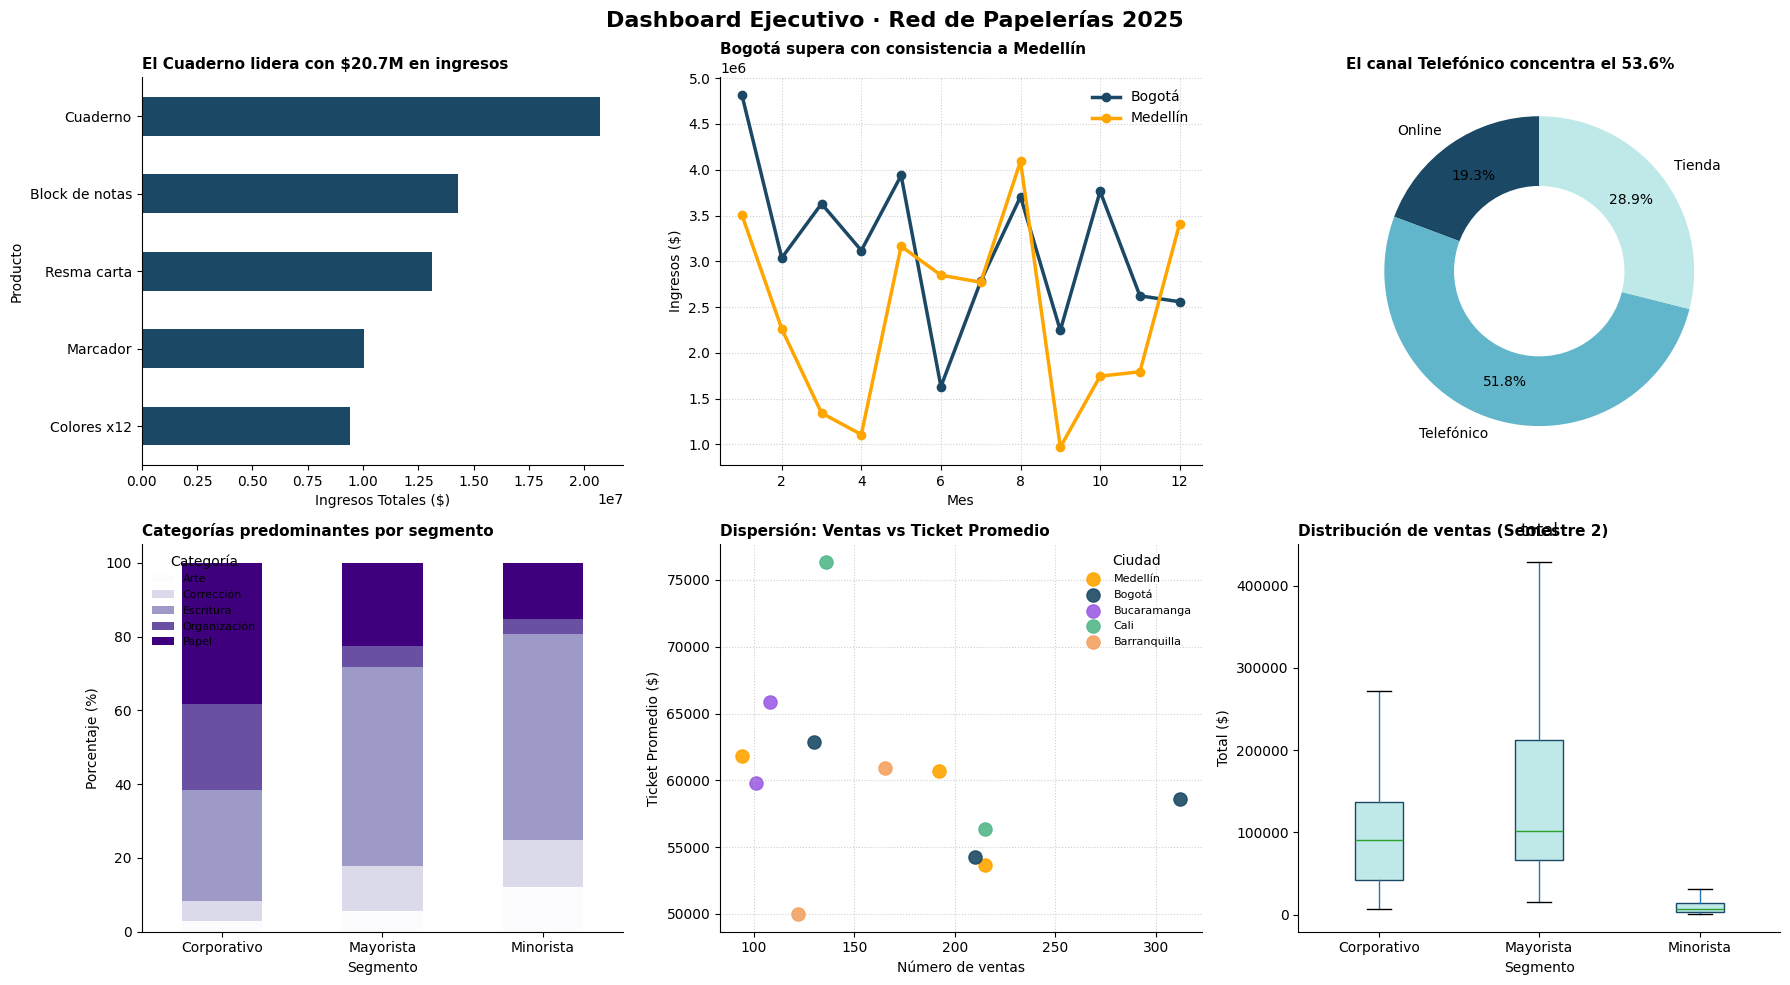

Hallazgos:
• El producto estrella de la cadena es el Cuaderno, el cual genera ingresos totales por $20.71 millones de pesos, consolidándose como el artículo prioritario para el inventario del próximo año.
• El canal Telefónico es el motor principal de comercialización de la cadena, abarcando el 53.6% de los ingresos totales ($61.45 millones de pesos frente a los demás canales).
• Durante el segundo semestre del año se registraron exactamente 1,050 ventas, evidenciando un comportamiento estable y una distribución similar en el valor de las transacciones entre los clientes minoristas y corporativos.


In [ ]:
mostrar(figura_elegida)

print("Hallazgos:")
for h in hallazgos:
    print("•", h)

### Ejercicio 12 · Publica tu notebook en GitHub
GitHub muestra los notebooks **con sus figuras**, así que tu notebook publicado es tu dashboard. Solo necesitas una cuenta gratuita en [github.com](https://github.com).

**Antes de publicar:**
- Ejecuta todo el notebook de arriba abajo (*Entorno de ejecución → Ejecutar todo*) para que las figuras queden guardadas en las salidas.
- **Nunca escribas tu API key dentro de una celda.** Los *Secrets* de Colab no se guardan en el notebook y por eso son seguros; el repositorio será público.

**Pasos:**
1. **Crea el repositorio:** botón **New** → nombre `mi-dashboard-ventas` → **Public** → *Create repository*.
2. **Guarda el notebook en GitHub.** Opción A: en Colab, *Archivo → Guardar una copia en GitHub*, autoriza, elige tu repositorio y acepta. Opción B: *Archivo → Descargar → .ipynb* y, en el repositorio, **Add file → Upload files** y arrastra el archivo.
3. **Abre el notebook en el repositorio** (haz clic en el archivo `.ipynb`): GitHub lo dibuja con tus figuras.
4. **Copia el enlace** de la barra del navegador. Debe verse así: `https://github.com/TU-USUARIO/mi-dashboard-ventas/blob/main/NOMBRE.ipynb`
5. **Compruébalo:** ábrelo en una ventana de incógnito. Si lo ves sin iniciar sesión, está público.

**Si no se ven las figuras:** vuelve a Colab, ejecuta todo y guarda de nuevo. Si GitHub dice *Unable to render code block*, recarga la página unos segundos después.

---
**Para entregar:** (1) el **enlace público** de tu notebook en GitHub, con tu dashboard final visible, y (2) tus prompts (`prompt_v1`, `prompt_v2` y, si la hiciste, `prompt_v3`) más **tres líneas** sobre qué tuviste que corregir de lo que hizo Gemini y cómo lo pediste (escríbelas en una celda de texto al final del notebook).